# MNIST classification grid search

## import

In [3]:
import numpy as np
import math
from modules.func import LINEAR, TANH, RELU, LOGSIG
from modules.model import Whittington_Model,LA_model
from modules.batch import expand_one_hot_vector,reduct_pred
import pandas as pd
import h5py
from datetime import datetime
import os
import matplotlib.pyplot as plt
import seaborn as sns

#download MNIST
from keras.datasets import mnist, fashion_mnist
# (train_image, train_label), (test_image, test_label) = mnist.load_data()
# train_image = train_image / 255.0
# test_image  = test_image / 255.0

# Fashion-MNIST
(train_image, train_label), (test_image, test_label) = fashion_mnist.load_data()
train_image = train_image.astype(np.float32) / 255.0

## Run

In [5]:
# parameter range (learning rates)
lr_x_min = 10**(-2)
lr_x_max = 10**(0)
lr_weight_min = 10**(-2)
lr_weight_max = 10**(0)
inc_range = 10 #multiplicative step of the search

# training settings
num_trial  = 1          # number of trials
num_step   = 1*10**5    # number of steps
num_test   = 500        # number of test images per accuracy evaluation
num_loop   = 50         # number of inference loops
num_batch  = 20         # batch size
test_trial = 40         # number of accuracy evaluations per trial

# model settings
x_dim = [784, 100, 10]  #number of cells per layer
f = LINEAR              #activation function (LINEAR, TANH, RELU, LOGSIG)

# initial value for the search
best_accuracy = -1

# list
log_lr_x = []
log_lr_weight = []
accuracy_result = []

lr_weight = lr_weight_min
while lr_weight < lr_weight_max:
    lr_x = lr_x_min
    accuracy_list_lr = []
    while lr_x < lr_x_max:
        print("Searching: lr_x=",lr_x,",lr_weight=",lr_weight)

        # choose the model
        model = LA_model(x_dim, num_batch, lr_x, lr_weight, f) #Whittington, LA_model

        accuracy_list = []

        # run the simulation
        for _tri in range(num_trial):
            accuracy_list_tmp = []

            for step in range(int((num_step)/num_batch)):
                idx    = np.random.randint(0, train_image.shape[0], num_batch)
                inputs = train_image[idx].reshape(num_batch , -1)
                target = expand_one_hot_vector(train_label[idx],num_batch,x_dim[-1])

                model.initialize_states()                   # reset activities
                model.update_x(inputs, target, num_loop)    # update x
                model.update_weight()                       # weight update

                # evaluate test accuracy
                if (step + 1) % int((num_step)/num_batch/test_trial) == 0 or step == 0:
                    cnt = 0
                    for _test in range(int(num_test/num_batch)):
                        idx    = np.random.randint(0, test_image.shape[0], num_batch)
                        inputs = test_image[idx].reshape(num_batch , -1)
                        model.initialize_states()
                        pred_vec= model.predict(inputs)
                        pred_list = reduct_pred(pred_vec, num_batch, x_dim[-1])
                        cnt += np.count_nonzero(pred_list == test_label[idx])
                    accuracy_list_tmp.append(cnt / num_test)

            accuracy_list.append(accuracy_list_tmp)
        
        log_lr_x.append(math.log10(lr_x))
        log_lr_weight.append(math.log10(lr_weight))
        accuracy_list_lr .append(accuracy_list)
        lr_x *= inc_range
    accuracy_result .append(accuracy_list_lr)
    lr_weight *= inc_range

accuracy = np.array(accuracy_result)
print("accuracy_array shape =", accuracy.shape)


Searching: lr_x= 0.01 ,lr_weight= 0.01
Searching: lr_x= 0.1 ,lr_weight= 0.01
Searching: lr_x= 0.01 ,lr_weight= 0.1


c:\Users\qipqi\LA\modules\model.py:143: RuntimeWarning: overflow encountered in square
  F_t = -np.sum([np.sum(np.square(ei)) for ei in self.e]) # update F_t
c:\Users\qipqi\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\_core\fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
c:\Users\qipqi\LA\modules\model.py:144: RuntimeWarning: invalid value encountered in scalar subtract
  diff = F_t - F_prev #change in error
c:\Users\qipqi\LA\modules\model.py:141: RuntimeWarning: overflow encountered in matmul
  self.e[i] = self.x[i+1] - (self.f(self.x[i]) @ self.U[i]) - self.b[i]
c:\Users\qipqi\LA\modules\model.py:141: RuntimeWarning: invalid value encountered in matmul
  self.e[i] = self.x[i+1] - (self.f(self.x[i]) @ self.U[i]) - self.b[i]
c:\Users\qipqi\LA\modules\model.py:136: RuntimeWarning: invalid value encountered in matmul
  dx = self.e[i-1] - (self.e[i] @ self.U_FB[i].T) * self.f.deriv(self.x[i])


Searching: lr_x= 0.1 ,lr_weight= 0.1
accuracy_array shape = (2, 2, 1, 41)


# Save

In [ ]:
# timestamp
timestamp = datetime.now().strftime("%Y%m%d%H%M%S")
func = f.get_name()
filename = f"{num_trial}trial_{num_step}step_{func}_{timestamp}"

# Save
save_dir = "./gs_result"
os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(save_dir, f"result_{filename}.h5")
with h5py.File(save_path, "w") as f:
    f.create_dataset("accuracy", data=accuracy, dtype=np.float32)
    f.create_dataset("log_lr_x", data=np.array(log_lr_x), dtype=np.float32)
    f.create_dataset("log_lr_weight", data=np.array(log_lr_weight), dtype=np.float32)

print(f"Saved: result_{filename}.h5")

Saved: result_data_20251211173357.txt.h5


## Load data

In [52]:
# load data
file_name = f"result_{filename}.h5"
save_dir = "./gs_result"
load_path = os.path.join(save_dir, file_name)
with h5py.File(load_path, "r") as f:
    accuracy = f["accuracy"][:]    # shape = [lr_w, lr_x, trial, test_trial]
    log_lr_x = f["log_lr_x"][:]
    log_lr_w = f["log_lr_weight"][:]

## Visualization

accuracy shape = (2, 2, 1, 41)


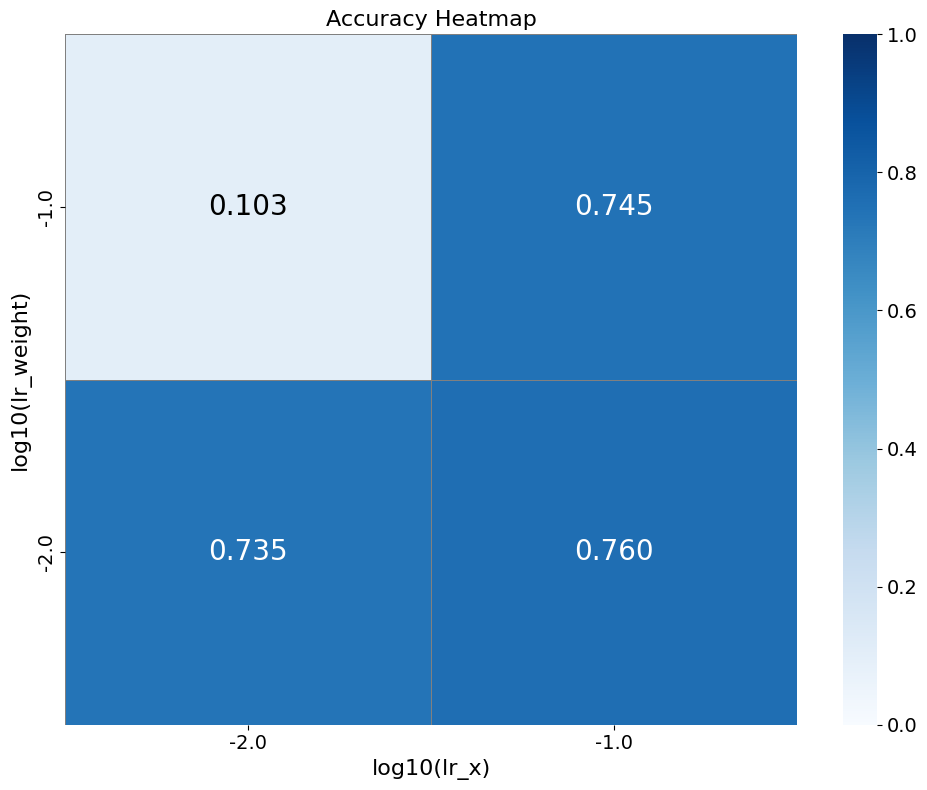

In [6]:
# settings
use_last_n = 10 # average over the last n test points
use_overall = False # True: average over all points, False: average over the last n 

num_lr_w, num_lr_x, num_trial, test_trial = accuracy.shape

print("accuracy shape =", accuracy.shape) # averaging 
if use_overall: accuracy_mean = accuracy.mean(axis=(2, 3)) # mean over trials and all test points 
else: 
    if use_last_n > test_trial: 
        raise ValueError("use_last_n > test_trial. Please adjust the values.")
    accuracy_last = accuracy[:, :, :, -use_last_n:] 
    accuracy_mean = accuracy_last.mean(axis=(2, 3))

# draw the heatmap
plt.figure(figsize=(10, 8))

# seaborn puts index 0 at the top, so flip vertically
heatmap_data = accuracy_mean[::-1]  # largest log_lr_weight at the top

# tick labels (flipped, otherwise they are upside down)
xticklabels = [f"{v:.1f}" for v in sorted(set(log_lr_x))]
yticklabels = [f"{v:.1f}" for v in sorted(set(log_lr_weight))[::-1]]


# build the annotations
annot_data = np.empty_like(heatmap_data, dtype=object)
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        val = heatmap_data[i, j]
        annot_data[i, j] = "NaN" if np.isnan(val) else f"{val:.3f}"

# plot
ax = sns.heatmap(
    heatmap_data,
    annot=False,
    cmap="Blues",
    linewidths=0.5, linecolor="gray",
    xticklabels=xticklabels,
    yticklabels=yticklabels,
    vmin=0, vmax=1
)

# write the values in the cells
n_rows, n_cols = heatmap_data.shape
for i in range(n_rows):
    for j in range(n_cols):
        val = heatmap_data[i, j]
        text = "NaN" if np.isnan(val) else f"{val:.3f}"
        color = "black" if np.isnan(val) or val <= 0.5 else "white"
        ax.text(j + 0.5, i + 0.5, text,
                ha='center', va='center',
                fontsize=20, color=color)

# axis labels and title
ax.tick_params(axis='both', labelsize=14)

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14)

ax.set_xlabel("log10(lr_x)", fontsize=16)
ax.set_ylabel("log10(lr_weight)", fontsize=16)
plt.title("Accuracy Heatmap", fontsize=16)

plt.tight_layout()
plt.show()


# Visualize earlier grid search results (from a CSV file)

In [ ]:
def mean_acc(text: str, n: int): # mean of the last n entries
    l = eval(text)
    if not l: return np.nan
    l = l[-min(n, len(l)):]
    return np.mean(l)

#grid_search_{Setting}_{name}.csv
df = pd.read_csv("gs_FM_4layer_PCLA_1trial_1000000step_TANH.csv") #File name
df["mean_accuracy"] = df["accuracy_list"].apply(lambda x: mean_acc(x, 10))
df
df=df[["log_trial",'-log10_lr_cortex','-log10_lr_weight',"mean_accuracy"]].groupby("log_trial").mean().reset_index()
df

NameError: name 'pd' is not defined

In [ ]:
# overwrite the lists from the original code with the recomputed values
log_lr_cortex = df['-log10_lr_cortex'].tolist()
log_lr_weight = df['-log10_lr_weight'].tolist()
# use the recomputed mean accuracy
log_mean_acc  = df["mean_accuracy"].tolist()

# sorted candidate log10 values (NaN ignored)
log_lr_cortex_set = sorted(df['-log10_lr_cortex'].dropna().unique())
log_lr_weight_set = sorted(df['-log10_lr_weight'].dropna().unique())

# lookup tables
lr_cortex_to_idx = {v: i for i, v in enumerate(log_lr_cortex_set)}
lr_weight_to_idx = {v: i for i, v in enumerate(log_lr_weight_set)}

# build the heatmap matrix
heatmap_data = np.full((len(log_lr_cortex_set), len(log_lr_weight_set)), np.nan)

# fill in the values (zip and if, so that NaN does not raise an error)
for lc, lw, acc in zip(log_lr_cortex, log_lr_weight, log_mean_acc):
    # skip if the parameter itself is NaN
    if np.isnan(lc) or np.isnan(lw):
        continue
    i = lr_cortex_to_idx[lc]
    j = lr_weight_to_idx[lw]
    heatmap_data[i, j] = acc

# flip heatmap_data vertically
heatmap_data_flipped = heatmap_data[::-1]

# flip yticklabels to match
yticklabels_flipped = [f"{v:.1f}" for v in log_lr_cortex_set[::-1]]

# build annotation strings, including NaN
annot_data = np.empty_like(heatmap_data, dtype=object)
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        if np.isnan(heatmap_data[i, j]):
            annot_data[i, j] = "NaN"
        else:
            # use .3f for more digits
            annot_data[i, j] = f"{heatmap_data[i, j]:.3f}"

# draw the heatmap (annot=False; values are written by hand below)
plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    heatmap_data_flipped,
    annot=False,
    xticklabels=[f"{v:.1f}" for v in log_lr_weight_set],
    yticklabels=yticklabels_flipped,
    cmap="Blues",
    linewidths=0.5, linecolor='gray',
    cbar=True, vmin=0, vmax=1
)

# annotations
n_rows, n_cols = heatmap_data_flipped.shape
for i in range(n_rows):
    for j in range(n_cols):
        val = heatmap_data_flipped[i, j]
        text = "NaN" if np.isnan(val) else f"{val:.3f}"
        color = "black" if np.isnan(val) or val <= 0.5 else "white"
        ax.text(j + 0.5, i + 0.5, text, ha='center', va='center', fontsize=20, fontname='DejaVu Sans',color=color)

# axis labels and title
ax.tick_params(axis='both', labelsize=18)  # <- tick label font size
# larger font for the color bar too
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=20)

ax.set_xlabel(r'$log_{10}(lr\_weight)$', fontsize=20)
ax.set_ylabel(r'$log_{10}(lr\_cortex)$', fontsize=20)
plt.title("Grid Search", fontsize=20)
plt.tight_layout()
plt.show()